In [34]:
import pandas as pd
from sqlalchemy import create_engine
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('clean_data.csv',low_memory=False)

In [5]:
# Kreira lokalnu SQLite bazu u fajlu (nema šifri, nema podešavanja servera!)
engine = create_engine('sqlite:///customer_analysis.db')

# Upisivanje očišćenog DataFrame-a u tabelu 'data'
df.to_sql('data', con=engine, if_exists='replace', index=False)

530104

In [6]:
query = 'SELECT * FROM data LIMIT 5;'
df_result = pd.read_sql(query, con=engine)
display(df_result)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,8.55
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,9.39
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,10.75
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,9.39
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,9.39


In [7]:
## Sum of rows, sum of revenue and sum of quantity
query1 = """
    SELECT 
        COUNT(*) AS total_transactions,
        SUM(Revenue) AS total_revenue,
        SUM(Quantity) AS total_quantity
    FROM data;
"""
pd.read_sql(query1, con=engine)

,total_transactions,total_revenue,total_quantity
0,530104,7659823.774,5588376


In [8]:
## Top 10 products by sum of revenue
query2 = """
    SELECT 
        Description,
        SUM(Quantity) AS total_quantity,
        SUM(Revenue) AS total_revenue
    FROM data
    GROUP BY Description
    ORDER BY total_revenue DESC
    LIMIT 10;
"""
pd.read_sql(query2, con=engine)

,Description,total_quantity,total_revenue
0,DOTCOM POSTAGE,706,206954.77
1,Manual,7225,81333.78
2,"PAPER CRAFT , LITTLE BIRDIE",80995,80997.08
3,MEDIUM CERAMIC TOP STORAGE JAR,78033,78400.12
4,WORLD WAR 2 GLIDERS ASSTD DESIGNS,55047,55219.20
5,JUMBO BAG RED RETROSPOT,48474,53723.29
6,WHITE HANGING HEART T-LIGHT HOLDER,37891,45363.97
7,REGENCY CAKESTAND 3 TIER,13879,42070.46
8,ASSORTED COLOUR BIRD ORNAMENT,36461,39025.49
9,POSTAGE,3150,38142.23


In [9]:
## Anomalies detection- products with small quantity and high revenue
query3 = """
    SELECT 
        Description,
        Quantity,
        Revenue
    FROM data
    WHERE Quantity <= 5 AND Revenue > 2000
    ORDER BY Revenue DESC;
"""
pd.read_sql(query3, con=engine)

,Description,Quantity,Revenue
0,AMAZON FEE,1,13542.33
1,Adjust bad debt,1,11063.06
2,POSTAGE,1,8143.75
3,DOTCOM POSTAGE,1,4506.17
4,Manual,1,4288.63
5,Manual,1,4162.06
6,Manual,1,4162.06
7,Manual,1,3950.32
8,Manual,1,3156.95
9,Manual,1,2654.95


In [12]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [13]:
## Definition of last date(day after last transaction)
snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)

In [14]:
## Group data by customer
rfm = df.groupby('CustomerID').agg(
    {
        'InvoiceDate': lambda x: (snapshot_date - x.max()).days,  # Recency
        'InvoiceNo': 'nunique',  # Frequency
        'Revenue': 'sum',  # Monetary
    }
)

In [15]:
## Column renaming
rfm.columns = ['Recency', 'Frequency', 'Monetary']

In [16]:
## Transfomation numerical values into marks from 1 to 4, with goal to divide it into segments lately
r_labels = range(4, 0, -1)
f_labels = range(1, 5)
m_labels = range(1, 5)

In [17]:
rfm['R'] = pd.qcut(rfm['Recency'], q=4, labels=r_labels)
# In case that have many duplicate values will be used method 'first'
rfm['F'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=4, labels=f_labels)
rfm['M'] = pd.qcut(rfm['Monetary'], q=4, labels=m_labels)

In [18]:
# Creation sum of RFM score
rfm['RFM_Score'] = (
    rfm['R'].astype(str) + rfm['F'].astype(str) + rfm['M'].astype(str)
)

In [19]:
display(rfm.head())

,Recency,Frequency,Monetary,R,F,M,RFM_Score
CustomerID,,,,,,,
12346.0,326,1,74216.04,1,1,4,114
12347.0,2,7,2939.21,4,4,4,444
12348.0,75,4,2519.71,2,3,4,234
12349.0,19,1,1236.10,3,1,3,313
12350.0,310,1,262.30,1,1,2,112


In [ ]:
## CustomerId 12346.0 has score 114- last shopping 326days; just one transaction; spend big amount of money near 74000

In [ ]:
# With purpose to transform this number into understandable business segment it will be mapped into score's segments

In [20]:
def rfm_segment(row):
  if row['R'] >= 3 and row['F'] >= 3:
    return 'Champions / Loyal'
  elif row['R'] >= 3 and row['F'] < 3:
    return 'Recent / Potential'
  elif row['R'] < 3 and row['F'] >= 3:
    return 'At Risk / Need Attention'
  else:
    return 'Lost / Hibernating'


rfm['Segment'] = rfm.apply(rfm_segment, axis=1)

# Let's see how much customers are in each segment
print(rfm['Segment'].value_counts())

Segment
Champions / Loyal           1523
Lost / Hibernating          1504
Recent / Potential           665
At Risk / Need Attention     646
Name: count, dtype: int64


In [ ]:
# There are higest number of loyal customers(1523), then lost(1504); this indicates churn(customer departure)
# and more than half smaller are recent and at risk

In [ ]:
# Cohort/Retention analysis -  purpose answer on question: 
#"Do our customers continue to buy after the first month, or do they only come back once?"

In [21]:
# define transaction mounth (in format YYYY-MM)
def get_month(x):
  return pd.to_datetime(x).to_period('M')


df['InvoiceMonth'] = df['InvoiceDate'].apply(get_month)

In [23]:
# Find the first mounth of purchase for each customer separately(Cohort Month)
df['CohortMonth'] = df.groupby('CustomerID')['InvoiceMonth'].transform('min')

In [24]:
# 4. Calculate the cohort index (number of months elapsed since the first purchase)
def get_date_int(df, column):
  year = df[column].dt.year
  month = df[column].dt.month
  return year, month

In [25]:
invoice_year, invoice_month = get_date_int(df, 'InvoiceMonth')
cohort_year, cohort_month = get_date_int(df, 'CohortMonth')

In [26]:
years_diff = invoice_year - cohort_year
months_diff = invoice_month - cohort_month
df['CohortIndex'] = years_diff * 12 + months_diff + 1

In [27]:
cohort_data = (
    df.groupby(['CohortMonth', 'CohortIndex'])['CustomerID']
    .apply(lambda x: x.nunique())
    .reset_index()
)

In [28]:
cohort_pivot = cohort_data.pivot(
    index='CohortMonth', columns='CohortIndex', values='CustomerID'
)

In [29]:
cohort_size = cohort_pivot.iloc[:, 0]
retention_matrix = cohort_pivot.divide(cohort_size, axis=0) * 100

In [30]:
display(retention_matrix.round(2))

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2010-12,100.0,36.61,32.32,38.42,36.27,39.77,36.27,34.92,35.37,39.55,37.40,50.28,26.55
2011-01,100.0,22.06,26.62,23.02,32.13,28.78,24.70,24.22,29.98,32.61,36.45,11.75,NaN
2011-02,100.0,18.68,18.68,28.42,27.11,24.74,25.26,27.89,24.74,30.53,6.84,NaN,NaN
2011-03,100.0,15.04,25.22,19.91,22.35,16.81,26.77,23.01,27.88,8.63,NaN,NaN,NaN
2011-04,100.0,21.33,20.33,21.00,19.67,22.67,21.67,26.00,7.33,NaN,NaN,NaN,NaN
2011-05,100.0,19.01,17.25,17.25,20.77,23.24,26.41,9.51,NaN,NaN,NaN,NaN,NaN
2011-06,100.0,17.36,15.70,26.45,23.14,33.47,9.50,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,18.09,20.74,22.34,27.13,11.17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.71,24.85,24.26,12.43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


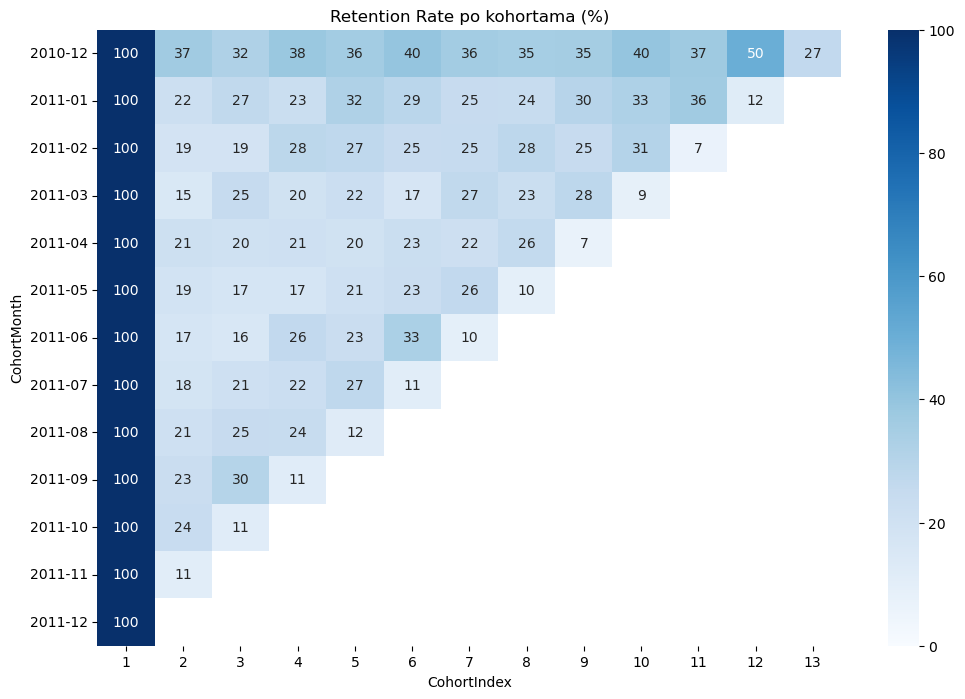

In [35]:
plt.figure(figsize=(12, 8))
plt.title('Retention Rate po kohortama (%)')
sns.heatmap(
    retention_matrix, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=100
)
plt.show()

In [ ]:
# First customers are loyal(30-40% in some month 50%), but in time loyality decrese in 3th and 4th month it is 11-21%

In [36]:
# Grouping by country and calculation of total revenue, quantity and number of orders
country_analysis = (
    df.groupby('Country')
    .agg({'Revenue': 'sum', 'Quantity': 'sum', 'InvoiceNo': 'nunique'})
    .sort_values(by='Revenue', ascending=False)
)

display(country_analysis.head(10))

,Revenue,Quantity,InvoiceNo
Country,,,
United Kingdom,6529958.034,4662390,18019
Netherlands,206608.730,200361,94
EIRE,185662.950,147173,288
Germany,152793.140,119261,457
France,149095.790,112103,392
Australia,87513.500,83901,57
Sweden,37778.790,36083,36
Spain,37444.340,27940,90
Switzerland,37263.360,30629,54


In [ ]:
# UK is dominating country with revenue(~6.5mil eur), sold quantity ~4.6mil peaces and 18010 transactions.
# On the second place is Netherlands ~206 600, 3th place EIRE ~185600, and 4th Germany ~152700.
# On second place for number of transactions is Germany, 3th is EIRE and on the 4th place Netherlands. 

In [ ]:
## Save tables in SQLite db

In [37]:
## RFM table
rfm.to_sql('rfm_segments', con=engine, if_exists='replace', index=True)

4338

In [39]:
# Retention Matrix
retention_matrix.index = retention_matrix.index.astype(str)
retention_matrix.to_sql(
    'cohort_retention', con=engine, if_exists='replace', index=True
)

13

In [ ]:
# In customer_analysis.db are data(clear transaction), rfm_segments(customers with scors and segments)
# and Cohort_retention (calculated % retention by months).

In [40]:
pd.read_sql('SELECT * FROM data', con=engine).to_csv(
    'cleaned_retail_data.csv', index=False
)
pd.read_sql('SELECT * FROM rfm_segments', con=engine).to_csv(
    'rfm_segments.csv', index=False
)
pd.read_sql('SELECT * FROM cohort_retention', con=engine).to_csv(
    'cohort_retention.csv', index=False
)

In [41]:
df.head(1)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,InvoiceMonth,CohortMonth,CohortIndex
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,8.55,2010-12,2010-12,1
